# Practical No. 9 — Build a Simple GAN to Generate Handwritten Digits Using MNIST Dataset

**Aim:** To implement a Generative Adversarial Network (GAN) for generating realistic handwritten digit images using the MNIST dataset.

**Objectives (from DL-Practicals.docx)**
- Understand GANs.
- Design Generator and Discriminator networks.
- Train a GAN on MNIST handwritten digits.
- Generate synthetic digit images and visualize them.

## Theory
A **Generative Adversarial Network (GAN)**, introduced by Ian Goodfellow (2014), consists of two competing neural networks:
- **Generator (G):** Creates fake images from random noise and learns to generate realistic samples.
- **Discriminator (D):** Determines whether an image is real or fake.

**Working process:** Random Noise → Generator → Fake Image; Real Image + Fake Image → Discriminator → Real (1) or Fake (0).

**Applications described in the document:** Image generation, face synthesis, image super-resolution, art generation, data augmentation, deepfake creation and medical imaging.

**MNIST:** 60,000 training images and 10,000 test images; grayscale; 28 × 28 pixels; digits 0–9.

**GAN objective (as in the document):**

\[\min_G\max_D V(D,G)=\mathbb E_{x\sim p_{data}(x)}[\log D(x)]+\mathbb E_{z\sim p_z(z)}[\log(1-D(G(z)))]\]

Here G is the generator, D the discriminator, x a real image and z random noise.

## Software Requirements
Python 3.x, TensorFlow/Keras, NumPy and Matplotlib. Run in **Google Colab**, ideally with a GPU (Runtime → Change runtime type), or using a Python kernel in VS Code.

## Algorithm
1. Load MNIST. 2. Normalize images. 3. Build generator. 4. Build discriminator. 5. Combine GAN. 6. Train discriminator on real/fake images. 7. Train generator to fool discriminator. 8. Repeat for multiple iterations. 9. Generate digits. 10. Visualize them.

**Execution note:** The Word document specifies **10,000 training iterations**, batch size **64** and a 100-dimensional noise vector. The quick-run default below is **1,000 iterations** to make local testing manageable; set `epochs = 10000` for the document's complete training schedule. Report actual outputs from your own run, not the Word document's sample numbers.

## Step 1: Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, LeakyReLU
from tensorflow.keras.optimizers import Adam
print('TensorFlow:', tf.__version__)

TensorFlow: 2.22.0-rc0


## Step 2: Load MNIST Dataset and Normalize
Keep raw images as `uint8` in memory; scale only each sampled training batch to `[-1, 1]`. This implements the document’s normalization while avoiding a full-size float copy that can cause local memory errors.

In [2]:
(X_train, _), (_, _) = mnist.load_data()
# 60,000 × 28 × 28, grayscale; do not create a large float32 duplicate.
X_train = X_train.reshape(X_train.shape[0], 784)
print('Training dataset shape:', X_train.shape)
print('Memory-efficient storage:', X_train.dtype)

Training dataset shape: (60000, 784)
Memory-efficient storage: uint8


## Step 3: Build Generator
Matches the document: Dense 256 → 512 → 1024 → 784, LeakyReLU activations and tanh output.

In [3]:
def build_generator():
    model = Sequential(name='generator')
    model.add(Input(shape=(100,)))
    model.add(Dense(256))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Dense(512))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Dense(1024))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Dense(784, activation='tanh'))
    return model

generator = build_generator()
generator.summary()

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       803,600 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,486,352 (5.67 MB)

 Trainable params: 1,486,352 (5.67 MB)

 Non-trainable params: 0 (0.00 B)

## Step 4: Build Discriminator
Matches the document: Dense 512 → 256 → sigmoid output, binary crossentropy and Adam learning rate 0.0002.

In [4]:
def build_discriminator():
    model = Sequential(name='discriminator')
    model.add(Input(shape=(784,)))
    model.add(Dense(512))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Dense(256))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(loss='binary_crossentropy', optimizer=Adam(0.0002), metrics=['accuracy'])
    return model

discriminator = build_discriminator()
discriminator.summary()

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 533,505 (2.04 MB)

 Trainable params: 533,505 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

## Step 5: Create and Compile GAN
Freeze discriminator weights *within the combined GAN* so GAN updates train the generator, while discriminator training remains possible through its separately compiled model.

In [5]:
discriminator.trainable = False
gan = Sequential([generator, discriminator], name='gan')
gan.compile(loss='binary_crossentropy', optimizer=Adam(0.0002))
# The separately compiled discriminator keeps its own training function.
gan.summary()

Model: "gan"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ generator (Sequential)          │ (None, 784)            │     1,486,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ discriminator (Sequential)      │ (None, 1)              │       533,505 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,019,857 (7.71 MB)

 Trainable params: 1,486,352 (5.67 MB)

 Non-trainable params: 533,505 (2.04 MB)

## Step 6: Train GAN
The source specifies 10,000 iterations and batch size 64. Use `epochs = 10000` for full training; the initial 1,000-iteration setting helps confirm the experiment works locally. Training uses only small float32 batches, limiting RAM use.

In [6]:
epochs = 1000  # Change to 10000 to match DL-Practicals.docx exactly.
batch_size = 64
noise_dim = 100

for epoch in range(epochs):
    idx = np.random.randint(0, X_train.shape[0], batch_size)
    real_images = (X_train[idx].astype('float32') - 127.5) / 127.5
    noise = np.random.normal(0, 1, (batch_size, noise_dim)).astype('float32')
    fake_images = generator.predict(noise, verbose=0)

    d_loss_real = discriminator.train_on_batch(real_images, np.ones((batch_size, 1), dtype='float32'))
    d_loss_fake = discriminator.train_on_batch(fake_images, np.zeros((batch_size, 1), dtype='float32'))

    noise = np.random.normal(0, 1, (batch_size, noise_dim)).astype('float32')
    g_loss = gan.train_on_batch(noise, np.ones((batch_size, 1), dtype='float32'))

    if epoch % 1000 == 0 or epoch == epochs - 1:
        loss_value = float(g_loss[0] if isinstance(g_loss, (list, tuple)) else g_loss)
        print(f'Epoch {epoch}, Generator Loss: {loss_value:.4f}')

c:\Users\shree\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\backend\tensorflow\trainer.py:86: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


Epoch 0, Generator Loss: 0.8025
Epoch 999, Generator Loss: 0.0000


## Step 7: Generate Digits

In [7]:
noise = np.random.normal(0, 1, (10, 100)).astype('float32')
generated_images = generator.predict(noise, verbose=0)
generated_images = generated_images.reshape(10, 28, 28)
print('Generated image array shape:', generated_images.shape)

Generated image array shape: (10, 28, 28)


## Step 8: Display Generated Images

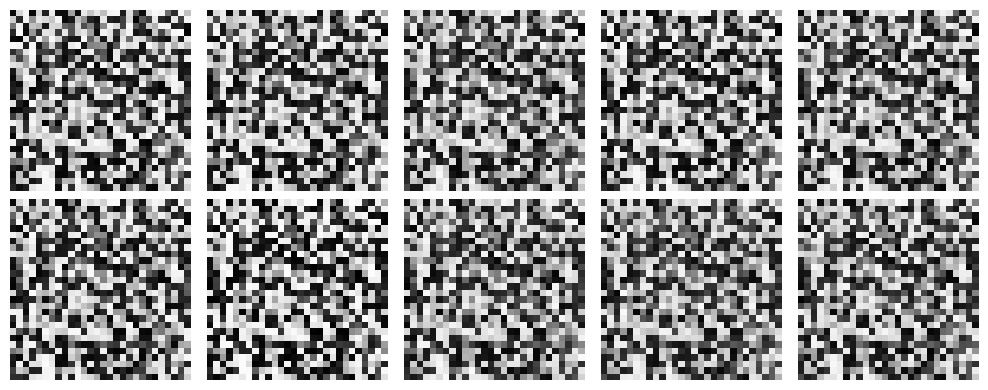

In [8]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(generated_images[i], cmap='gray', vmin=-1, vmax=1)
    plt.axis('off')
plt.tight_layout()
plt.show()

## Result
The practical demonstrates implementing a GAN with a Generator and Discriminator trained adversarially on MNIST to produce synthetic handwritten-digit images. Evaluate success from the **actual images and outputs** produced after executing the notebook.

*Source: DL-Practicals.docx, Practical No. 9. The Questions section is intentionally omitted.*